[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shulruferor-sudo/Advance-Data-Science/blob/main/projects/Bureau%20of%20Statistics/Assignment_Solution.ipynb)


# Assignment Solution for Position within Israel Central Bureau of Statistics organization

## Targets for the assignment

1. To show quality of data understanding, data analysis, dission making, and performing data trusformations following the dissitions for haw I see best data preporation before using it in any classifyer.

2. To show quality of classification understanding, model tuning, training tuning, and deverse assesments of path to choose best serve classification of this specific kind of dataset qualities.


In [21]:
# Standard library and notebook-wide utilities
import io
import hashlib
import urllib.request
import re
import json
import warnings
from pathlib import Path

# Keep the previous warning policy scoped to UserWarning, not all warnings.
warnings.filterwarnings('ignore', category=UserWarning)

# Numerical arrays and tabular survey data
import numpy as np
import pandas as pd

# Notebook display configuration: improve readability without changing data.
pd.set_option('display.html.use_mathjax', False)
pd.set_option('display.max_columns', None)

def custom_style(df):
    """Format DataFrames for notebook display; source values remain unchanged."""
    return (df.style.set_table_styles([
        {'selector': 'th', 'props': [
            ('background-color', '#1e293b'), ('color', '#ffffff'),
            ('font-family', 'sans-serif'), ('font-size', '13px'),
            ('padding', '10px 15px'), ('text-align', 'left')
        ]},
        {'selector': 'td', 'props': [
            ('font-family', 'sans-serif'), ('font-size', '12px'),
            ('padding', '8px 15px'), ('border-bottom', '1px solid #e2e8f0')
        ]},
        {'selector': 'tr:hover', 'props': [('background-color', '#f1f5f9')]}
    ]).set_properties(**{'background-color': '#f8fafc'}))

# Apply the HTML style to all DataFrame previews in this notebook session.
pd.DataFrame._repr_html_ = lambda self: custom_style(self)._repr_html_()

# Figures and rich notebook output
import matplotlib.pyplot as plt
from IPython.display import display, HTML

# Machine learning: cross-validation and reusable pipelines
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_val_predict
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline

# Candidate classifiers and majority-class baseline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.dummy import DummyClassifier

# Performance measurement
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Reproducibility: downstream model evaluation uses this fixed random seed.
SEED = 42



## Data preparation

First we need to upload from assignment excel the data and the metadata from the one file with two sheets.


In [32]:
# Retrieve the original workbook, verify its contents, and load both source tables.
URL = "https://raw.githubusercontent.com/shulruferor-sudo/Advance-Data-Science/main/Datasets/cbs_occupation_survey_sample/DUMMY_DATASET.xlsx"
SHA = "e1e7f391c0675dd14830eaae6b5cd114edc256f18b956bb48a454b0b1209e1ac"
raw = urllib.request.urlopen(URL, timeout=90).read()

# Load only rows and columns without missing values
survey_data = (pd.read_excel(io.BytesIO(raw), sheet_name="Survey Dataset").dropna(axis=0, how="all").dropna(axis=1, how="all"))

metadata = (pd.read_excel(io.BytesIO(raw), sheet_name="Metadata").dropna(axis=0, how="all").dropna(axis=1, how="any"))

# Display the complete metadata dictionary.
display(metadata)
print()

# Display the first three survey records.
display(survey_data)
print()

,משתנה,הסבר,פורמט
0,ID,מספר רץ,INTEGER
1,YeshuvAvoda,שם יישוב עבודה,TEXT
2,ShemAvoda,שם מקום העבודה שלך,TEXT
3,SugAvoda,הפעילות העיקרית של מקום העבודה,TEXT
4,ShemMachlaka,אגף או מחלקה שהנסקר עובד,TEXT
5,SugMachlaka,הפעילות העיקרית של האגף או המחלקה שהנסקר עובד,TEXT
6,EzoAvoda,עבודה שהנסקר עושה במקום עבודה זה,TEXT
7,TeurPeula,הפעולות העיקריות שהנסקר עושה במקום עבודה,TEXT
8,TeurTafkid,מהו תואר המשרה של הנסקר במקום עבודה זה (במידה ויש),TEXT
9,MenahelEtMi,האם הנסקר מנהל או ממונה על עובדים אחרים?,INTEGER


,ID,YeshuvAvoda,ShemAvoda,SugAvoda,ShemMachlaka,SugMachlaka,EzoAvoda,TeurPeula,TeurTafkid,MenahelEtMi,MaamadAvoda,MakorSachar,TeudaGvoha,shnotlimud,Gil,TarichHathala,SemelAnafSofi,SemelMishlachSofi
0,1.000000,ירושלים,"למ""ס","איסוף, עיבוד ופרסום נתונים",מיקרו כלכלה,טיפול בנתוני מיקרו,סגן מנהל אגף,"כנ""ל",סגן מנהל אגף,3.000000,1.000000,1.000000,6.000000,22.000000,55.000000,2020-06-15 00:00:00,8411,2120
1,2.000000,ירושלים,בית חולים הדסה עין כרם,טיפול בחולים,רדיואתרפיה,טיפול בחולי סרטן,טכנאית רדיותרפיה,"כנ""ל","כנ""ל",nan,1.000000,1.000000,6.000000,22.000000,55.000000,2022-07-01 00:00:00,8610,3311
2,3.000000,באר שבע,קריית הממשלה,מתן שירות למשתמשים באתר GOV,תמיכה בלקוחות,"כנ""ל",נותנת תמיכה ללקוחות שמבקשים עזרה,מסבירה איך להשתמש בשירותים ממשלתיים באתר האינטרנט,nan,nan,1.000000,1.000000,5.000000,15.000000,29.000000,2021-06-06 00:00:00,8411,3512
3,4.000000,תל אביב,משרד החינוך,בית ספר יסודי,שמירה,nan,שומר בבית הספר,nan,nan,nan,1.000000,2.000000,3.000000,12.000000,48.000000,2024-07-01 00:00:00,8010,5414
4,5.000000,תל אביב,אמיר כהן,מטפל בקשיש במשפחה,nan,nan,מטפל בקשיש,"נותן אוכל, עוזר בניקיון בית, עוזר להתרחץ",nan,nan,1.000000,1.000000,4.000000,14.000000,42.000000,2010-01-11 00:00:00,XXXX,5322
5,6.000000,חיפה,משטרה,שוטר,nan,nan,שוטר,nan,nan,nan,1.000000,1.000000,4.000000,14.000000,35.000000,2022-05-31 00:00:00,8423,5412
6,7.000000,קרית גת,אינטל,ייצור צ'יפים למחשבים,חדר נקי,nan,עובד בחדר נקי,מפקח על תהליך ייצור צ'יפים,nan,nan,1.000000,1.000000,5.000000,15.000000,65.000000,1999-07-07 00:00:00,2610,3122
7,8.000000,חיפה,אינטל,פיתוח תוכנה לצ'יפים,הנדסת תוכנה,nan,"מהנדס תוכנה, מנהל צוות עובדים",מפתח קוד לצ'יפים,nan,1.000000,1.000000,1.000000,6.000000,18.000000,55.000000,2000-11-10 00:00:00,7201,2512
8,9.000000,אשקלון,שופר סל,קופאית,nan,nan,קופאית,nan,nan,nan,1.000000,3.000000,2.000000,11.000000,52.000000,2022-11-11 00:00:00,4711,5230
9,10.000000,הרצליה,EMILIO,"הייטק, פיתוח תוכנה",nan,nan,מתכנת,nan,nan,nan,1.000000,1.000000,5.000000,16.000000,24.000000,2021-12-14 00:00:00,6201,2514


### Investigation

I examine each source field and the relationships between fields using the recorded answers and the metadata.  
The research questions appear beside the relevant code.  
Observed results provide the evidence for subsequent decisions.


### ID — Record Identifier

**Metadata:** Running index (`INTEGER`).

**Assignment:** A respondent may update and resubmit the same questionnaire during the survey period. The interpretation treats updates to an open questionnaire as changes to its existing record; `ID` is the record key.

**Question 1: Does each loaded survey record have a unique integer ID?**  
Check identifier completeness, numeric type, and duplicates.

**Question 2: Does ID form a consecutive running index from 1 to N?**  
Compare the observed identifiers with the expected sequence. Rows without an ID were excluded during data loading, so these checks apply to the retained records.


In [10]:
# Q1: Does every loaded survey record have a unique integer ID?
ids = pd.to_numeric(data["ID"], errors="coerce")
n_records = len(ids)
integer_ids = bool(ids.notna().all() and ids.mod(1).eq(0).all())
unique_ids = bool(ids.is_unique)

# Q2: Do IDs form the consecutive running sequence 1 through N?
consecutive = bool(integer_ids and unique_ids and np.array_equal(np.sort(ids.to_numpy(dtype=np.int64)), np.arange(1, n_records + 1)))

display(pd.DataFrame({"Records": [n_records], "Missing IDs": [int(ids.isna().sum())], "Unique IDs": [int(ids.nunique())],
                      "Integer IDs": [integer_ids], "Consecutive 1–N": [consecutive]}))

# Preserve this result for the subsequent 18-field audit summary.
FIELD_AUDITS["ID"] = {"field": "ID", "present": int(ids.notna().sum()), "missing": int(ids.isna().sum()),
                      "distinct": int(ids.nunique()), "claimed_present": 200, "claimed_distinct": 200,
                      "matches_slide": n_records == 200 and ids.nunique() == 200}

# Conclusion follows the measured result; the ID is not an occupation predictor.
print("ID is a valid unique, consecutive record index." if integer_ids and unique_ids and consecutive
      else "ID does not satisfy every running-index check.")


,Records,Missing IDs,Unique IDs,Integer IDs,Consecutive 1–N
0,200,0,200,True,True


NameError: name 'FIELD_AUDITS' is not defined

### YeshuvAvoda — Locality
**Questions:** האם שם היישוב נבחר מרשימה? · האם כתיבים שונים מציינים אותו מקום?

**Hypothesis and competing interpretation:** Different spellings can denote the same locality but are not proven equivalent solely by string differences.

**Decision subject to observed evidence:** Audit spelling variants and treat the field as geographic context, not as an occupation.

The next Python cell contains these exact questions and computes the evidence against the workbook.



FIELD: YeshuvAvoda
RESEARCH QUESTIONS:
Q1. האם שם היישוב נבחר מרשימה?
Q2. האם כתיבים שונים מציינים אותו מקום?
Observed: present=200, missing=0, distinct=21; records=200
Slide counts: present=200, distinct=21; verified=True
METADATA: field definition and source type


,משתנה,הסבר,פורמט,ערכים אפשריים
1,YeshuvAvoda,שם יישוב עבודה,TEXT,nan


ACTUAL RESPONSE FREQUENCIES:


,records
source_value,
תל אביב,35
ירושלים,21
חיפה,19
רעננה,13
הרצליה,13
אילת,13
באר שבע,11
חדרה,11
אשקלון,11


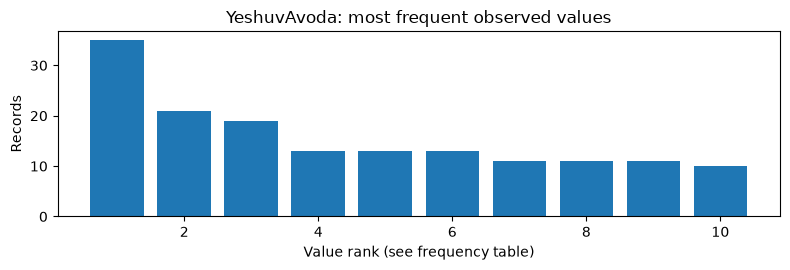

Potential variations containing קרי:


,records
YeshuvAvoda,
קרית גת,6
קריית גת,1


INFERENCE: merging קרית גת and קריית גת needs validated place identity.
OBSERVATION VS. INTERPRETATION: Different spellings can denote the same locality but are not proven equivalent solely by string differences.
DATA-PROCESSING DECISION: Audit spelling variants and treat the field as geographic context, not as an occupation.


In [ ]:
# FIELD INVESTIGATION: YeshuvAvoda — Locality
# Questions from the approved seven-slide presentation:
# Q1. האם שם היישוב נבחר מרשימה?
# Q2. האם כתיבים שונים מציינים אותו מקום?
QUESTIONS = ["האם שם היישוב נבחר מרשימה?","האם כתיבים שונים מציינים אותו מקום?"]
v = inspect_source_field('YeshuvAvoda', QUESTIONS, plot='category')
variants = v[v.fillna('').str.contains('קרי', regex=False)]
print('Potential variations containing קרי:')
display(variants.value_counts().to_frame('records'))
print('INFERENCE: merging קרית גת and קריית גת needs validated place identity.')
print('OBSERVATION VS. INTERPRETATION: Different spellings can denote the same locality but are not proven equivalent solely by string differences.')
print('DATA-PROCESSING DECISION: Audit spelling variants and treat the field as geographic context, not as an occupation.')


### ShemAvoda — Employer names and multilingual evidence
**Questions:** האם זה שם חברה רשמי? · כיצד אותה חברה מופיעה בעברית ובאנגלית?

**Hypothesis and competing interpretation:** Employer names include formal names, descriptions and multilingual variants; textual similarity does not prove corporate identity.

**Decision subject to observed evidence:** Preserve exact strings and investigate English-to-Hebrew employer candidates separately with LaBSE.

The next Python cell contains these exact questions and computes the evidence against the workbook.



FIELD: ShemAvoda
RESEARCH QUESTIONS:
Q1. האם זה שם חברה רשמי?
Q2. כיצד אותה חברה מופיעה בעברית ובאנגלית?
Observed: present=200, missing=0, distinct=82; records=200
Slide counts: present=200, distinct=82; verified=True
METADATA: field definition and source type


,משתנה,הסבר,פורמט,ערכים אפשריים
2,ShemAvoda,שם מקום העבודה שלך,TEXT,nan


ACTUAL RESPONSE FREQUENCIES:


,records
source_value,
מסעדה,10
משרד החינוך,9
בנק לאומי,7
משטרה,7
בית ספר תיכון,7
סופר פארם,6
קניון עזריאלי,6
אינטל,6
קוסמטיקאית עצמאית,5


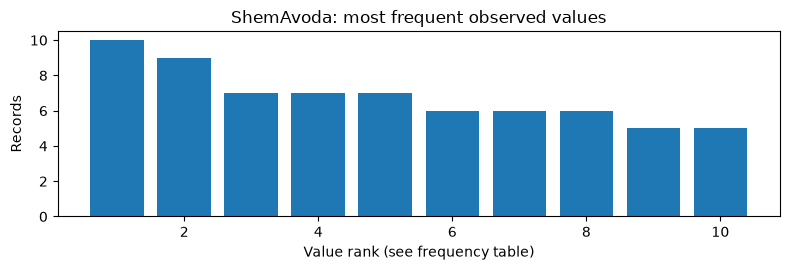

Employer records with Latin letters: 14
Employer records with mixed scripts: 1
Latin-containing employer descriptions: 14 record(s)


,ID,ShemAvoda
9,10,EMILIO
14,15,NVIDIA
37,38,INTEL
46,47,NVIDIA
55,56,COGNYTE
72,73,EMILIO
77,78,NVIDIA
100,101,INTEL
103,104,EMILIO
109,110,NVIDIA


NEXT QUESTION: compare only employer names with LaBSE; never assume an identity match.
OBSERVATION VS. INTERPRETATION: Employer names include formal names, descriptions and multilingual variants; textual similarity does not prove corporate identity.
DATA-PROCESSING DECISION: Preserve exact strings and investigate English-to-Hebrew employer candidates separately with LaBSE.


In [ ]:
# FIELD INVESTIGATION: ShemAvoda — Employer names and multilingual evidence
# Questions from the approved seven-slide presentation:
# Q1. האם זה שם חברה רשמי?
# Q2. כיצד אותה חברה מופיעה בעברית ובאנגלית?
QUESTIONS = ["האם זה שם חברה רשמי?","כיצד אותה חברה מופיעה בעברית ובאנגלית?"]
v = inspect_source_field('ShemAvoda', QUESTIONS, plot='category')
latin = v.fillna('').str.contains(r'[A-Za-z]', regex=True)
hebrew = v.fillna('').str.contains(r'[\u0590-\u05FF]', regex=True)
print('Employer records with Latin letters:', int(latin.sum()))
print('Employer records with mixed scripts:', int((latin & hebrew).sum()))
show_evidence(latin, ['ShemAvoda'], 'Latin-containing employer descriptions')
print('NEXT QUESTION: compare only employer names with LaBSE; never assume an identity match.')
print('OBSERVATION VS. INTERPRETATION: Employer names include formal names, descriptions and multilingual variants; textual similarity does not prove corporate identity.')
print('DATA-PROCESSING DECISION: Preserve exact strings and investigate English-to-Hebrew employer candidates separately with LaBSE.')


### SugAvoda — Employer activity
**Questions:** האם פעילות המעסיק היא משלח היד של העובד?

**Hypothesis and competing interpretation:** Employer activity is sector/workplace context, not necessarily a description of personal duties.

**Decision subject to observed evidence:** Analyze workplace activity separately, keeping unknown values explicit.

The next Python cell contains these exact questions and computes the evidence against the workbook.



FIELD: SugAvoda
RESEARCH QUESTIONS:
Q1. האם פעילות המעסיק היא משלח היד של העובד?
Observed: present=175, missing=25, distinct=78; records=200
Slide counts: present=175, distinct=78; verified=True
METADATA: field definition and source type


,משתנה,הסבר,פורמט,ערכים אפשריים
3,SugAvoda,הפעילות העיקרית של מקום העבודה,TEXT,nan


ACTUAL RESPONSE FREQUENCIES:


,records
source_value,
,25
מסעדה,7
בית ספר יסודי,7
חנות למכירת בגדים,7
אירוח,6
מכירת קוסמטיקה,5
עובד ניקיון,5
פיתוח תוכנה,4
מפעל חלקים אלקטרוניים,4


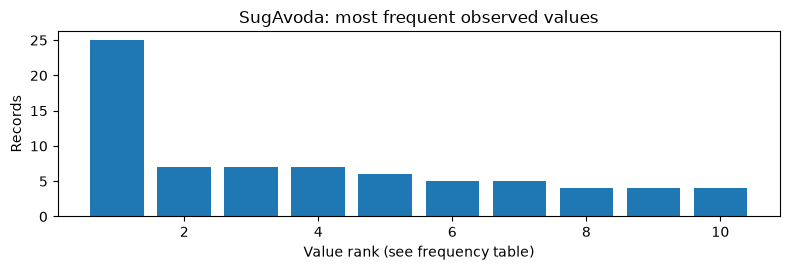

Missing employer activity alongside direct occupation descriptions: 25 record(s)


,ID,SugAvoda,EzoAvoda
16,17,nan,קוסמטיקאית
19,20,nan,עובדת סוציאלית במחלקת רווחה
25,26,nan,מנקה בית ספר אחרי הלימודים
27,28,nan,טבח
29,30,nan,אוסף תפוזים בפרדס של קיבוץ
44,45,nan,nan
48,49,nan,קוסמטיקאית
59,60,nan,טבח
61,62,nan,אוסף תפוזים בפרדס של קיבוץ
79,80,nan,קוסמטיקאית


Employer and performed-work strings differ in 170 records
INFERENCE: employer activity and respondent occupation are different concepts.
OBSERVATION VS. INTERPRETATION: Employer activity is sector/workplace context, not necessarily a description of personal duties.
DATA-PROCESSING DECISION: Analyze workplace activity separately, keeping unknown values explicit.


In [ ]:
# FIELD INVESTIGATION: SugAvoda — Employer activity
# Questions from the approved seven-slide presentation:
# Q1. האם פעילות המעסיק היא משלח היד של העובד?
QUESTIONS = ["האם פעילות המעסיק היא משלח היד של העובד?"]
v = inspect_source_field('SugAvoda', QUESTIONS, plot='category')
show_evidence(v.isna(), ['SugAvoda','EzoAvoda'],
              'Missing employer activity alongside direct occupation descriptions')
different = (original['SugAvoda'].astype('string').fillna('').str.strip()
             != original['EzoAvoda'].astype('string').fillna('').str.strip())
print('Employer and performed-work strings differ in', int(different.sum()), 'records')
print('INFERENCE: employer activity and respondent occupation are different concepts.')
print('OBSERVATION VS. INTERPRETATION: Employer activity is sector/workplace context, not necessarily a description of personal duties.')
print('DATA-PROCESSING DECISION: Analyze workplace activity separately, keeping unknown values explicit.')


### ShemMachlaka — Department identity
**Questions:** מה מוסיף שם המחלקה? · האם ריק פירושו שאין מחלקה?

**Hypothesis and competing interpretation:** A blank department name may be absent or unanswered; it is not proof that no unit exists.

**Decision subject to observed evidence:** Represent the department independently and retain the source missingness state.

The next Python cell contains these exact questions and computes the evidence against the workbook.



FIELD: ShemMachlaka
RESEARCH QUESTIONS:
Q1. מה מוסיף שם המחלקה?
Q2. האם ריק פירושו שאין מחלקה?
Observed: present=136, missing=64, distinct=61; records=200
Slide counts: present=136, distinct=61; verified=True
METADATA: field definition and source type


,משתנה,הסבר,פורמט,ערכים אפשריים
4,ShemMachlaka,אגף או מחלקה שהנסקר עובד,TEXT,nan


ACTUAL RESPONSE FREQUENCIES:


,records
source_value,
,64
שמירה,7
תמיכה בלקוחות,6
קוסמטיקה וטיפוח,6
משק,6
עובד ניקיון,6
מחלקת רווחה,5
חסוי,4
הנהלת חשבונות,4


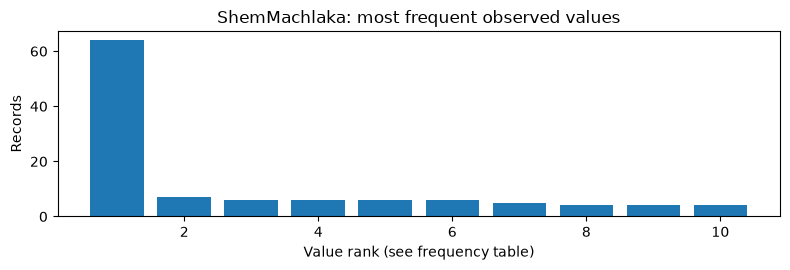

Department-name response rate: 68.0%
Missing department name with potentially recorded department activity: 64 record(s)


,ID,ShemMachlaka,SugMachlaka
4,5,nan,nan
5,6,nan,nan
8,9,nan,nan
9,10,nan,nan
12,13,nan,nan
14,15,nan,nan
16,17,nan,nan
18,19,nan,nan
21,22,nan,nan
22,23,nan,nan


OBSERVATION VS. INTERPRETATION: A blank department name may be absent or unanswered; it is not proof that no unit exists.
DATA-PROCESSING DECISION: Represent the department independently and retain the source missingness state.


In [ ]:
# FIELD INVESTIGATION: ShemMachlaka — Department identity
# Questions from the approved seven-slide presentation:
# Q1. מה מוסיף שם המחלקה?
# Q2. האם ריק פירושו שאין מחלקה?
QUESTIONS = ["מה מוסיף שם המחלקה?","האם ריק פירושו שאין מחלקה?"]
v = inspect_source_field('ShemMachlaka', QUESTIONS, plot='category')
print('Department-name response rate:', f'{v.notna().mean():.1%}')
show_evidence(v.isna(), ['ShemMachlaka','SugMachlaka'],
              'Missing department name with potentially recorded department activity')
print('OBSERVATION VS. INTERPRETATION: A blank department name may be absent or unanswered; it is not proof that no unit exists.')
print('DATA-PROCESSING DECISION: Represent the department independently and retain the source missingness state.')


### SugMachlaka — Department activity and contextual references
**Questions:** מדוע נשאלת גם פעילות המחלקה? · למה מתייחס כנ״ל?

**Hypothesis and competing interpretation:** The relative marker כנ״ל cannot be interpreted without a known earlier answer.

**Decision subject to observed evidence:** Keep department function and unresolved relative references separately.

The next Python cell contains these exact questions and computes the evidence against the workbook.



FIELD: SugMachlaka
RESEARCH QUESTIONS:
Q1. מדוע נשאלת גם פעילות המחלקה?
Q2. למה מתייחס כנ״ל?
Observed: present=66, missing=134, distinct=35; records=200
Slide counts: present=66, distinct=35; verified=True
METADATA: field definition and source type


,משתנה,הסבר,פורמט,ערכים אפשריים
5,SugMachlaka,הפעילות העיקרית של האגף או המחלקה שהנסקר עובד,TEXT,nan


ACTUAL RESPONSE FREQUENCIES:


,records
source_value,
,134
"כנ""ל",8
טיפול בחולי סרטן,4
טיפול באנשים עם בעיות,4
משחק,4
אריזה,3
טיפול בלקוחות עסקיים,3
תמיכה במערכות מחשוב של הבנק,3
חישובי שכר לעובדים,3


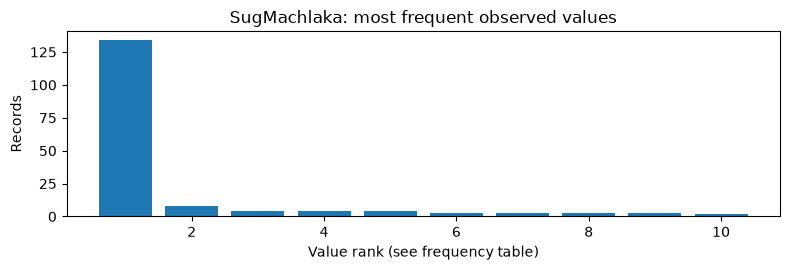

Relative-reference answers: 8
Which earlier field could a relative reference indicate?: 8 record(s)


,ID,SugAvoda,ShemMachlaka,SugMachlaka
2,3,מתן שירות למשתמשים באתר GOV,תמיכה בלקוחות,"כנ""ל"
33,34,תיקון קווי מים,תמיכה בלקוחות,"כנ""ל"
65,66,מתן שירות למשתמשים באתר GOV,תמיכה בלקוחות,"כנ""ל"
96,97,הספקת מים,הנדסה,"כנ""ל"
128,129,קבלת קהל,תמיכה בלקוחות,"כנ""ל"
164,165,קבלת קהל,תמיכה בלקוחות,"כנ""ל"
186,187,תיקון קווי חשמל,תמיכה בתקלות,"כנ""ל"
192,193,קבלת קהל,תמיכה בלקוחות,"כנ""ל"


DECISION: no automatic replacement until the reference is unambiguous.
OBSERVATION VS. INTERPRETATION: The relative marker כנ״ל cannot be interpreted without a known earlier answer.
DATA-PROCESSING DECISION: Keep department function and unresolved relative references separately.


In [ ]:
# FIELD INVESTIGATION: SugMachlaka — Department activity and contextual references
# Questions from the approved seven-slide presentation:
# Q1. מדוע נשאלת גם פעילות המחלקה?
# Q2. למה מתייחס כנ״ל?
QUESTIONS = ["מדוע נשאלת גם פעילות המחלקה?","למה מתייחס כנ״ל?"]
v = inspect_source_field('SugMachlaka', QUESTIONS, plot='category')
refs = v.fillna('').str.fullmatch(r'כנ["״]?ל')
print('Relative-reference answers:', int(refs.sum()))
show_evidence(refs, ['SugAvoda','ShemMachlaka','SugMachlaka'],
              'Which earlier field could a relative reference indicate?')
print('DECISION: no automatic replacement until the reference is unambiguous.')
print('OBSERVATION VS. INTERPRETATION: The relative marker כנ״ל cannot be interpreted without a known earlier answer.')
print('DATA-PROCESSING DECISION: Keep department function and unresolved relative references separately.')


### EzoAvoda — Performed work
**Questions:** איזה שדה מתאר מה האדם עושה בפועל?

**Hypothesis and competing interpretation:** Direct duties provide different evidence from employer business type or workplace name.

**Decision subject to observed evidence:** Retain direct performed-work text as occupational evidence.

The next Python cell contains these exact questions and computes the evidence against the workbook.



FIELD: EzoAvoda
RESEARCH QUESTIONS:
Q1. איזה שדה מתאר מה האדם עושה בפועל?
Observed: present=193, missing=7, distinct=84; records=200
Slide counts: present=193, distinct=84; verified=True
METADATA: field definition and source type


,משתנה,הסבר,פורמט,ערכים אפשריים
6,EzoAvoda,עבודה שהנסקר עושה במקום עבודה זה,TEXT,nan


ACTUAL RESPONSE FREQUENCIES:


,records
source_value,
שומר בבית הספר,7
,7
טבח,7
קוסמטיקאית,6
מנקה בית ספר אחרי הלימודים,6
מוכרת,6
מלצר,5
קופאית,5
חשדרנית,5


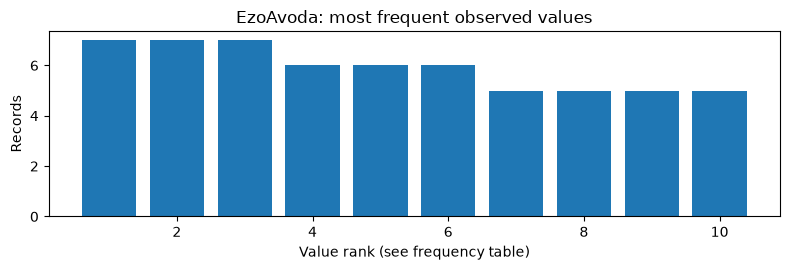

Unanswered performed-work field with remaining occupation evidence: 7 record(s)


,ID,EzoAvoda,TeurPeula,TeurTafkid
44,45,nan,nan,nan
107,108,nan,nan,nan
141,142,nan,nan,nan
163,164,nan,nan,nan
165,166,nan,nan,nan
170,171,nan,nan,מנהלת משאבי אנוש
192,193,nan,nan,nan


DECISION: direct duties remain separate from organizational context.
OBSERVATION VS. INTERPRETATION: Direct duties provide different evidence from employer business type or workplace name.
DATA-PROCESSING DECISION: Retain direct performed-work text as occupational evidence.


In [ ]:
# FIELD INVESTIGATION: EzoAvoda — Performed work
# Questions from the approved seven-slide presentation:
# Q1. איזה שדה מתאר מה האדם עושה בפועל?
QUESTIONS = ["איזה שדה מתאר מה האדם עושה בפועל?"]
v = inspect_source_field('EzoAvoda', QUESTIONS, plot='category')
show_evidence(v.isna(), ['EzoAvoda','TeurPeula','TeurTafkid'],
              'Unanswered performed-work field with remaining occupation evidence')
print('DECISION: direct duties remain separate from organizational context.')
print('OBSERVATION VS. INTERPRETATION: Direct duties provide different evidence from employer business type or workplace name.')
print('DATA-PROCESSING DECISION: Retain direct performed-work text as occupational evidence.')


### TeurPeula — Performed actions and references
**Questions:** מדוע נדרשות פעולות בנוסף לתיאור העבודה?

**Hypothesis and competing interpretation:** Task details can discriminate similar titles, but references such as כנ״ל need context.

**Decision subject to observed evidence:** Preserve tasks independently and flag unresolved references.

The next Python cell contains these exact questions and computes the evidence against the workbook.



FIELD: TeurPeula
RESEARCH QUESTIONS:
Q1. מדוע נדרשות פעולות בנוסף לתיאור העבודה?
Observed: present=64, missing=136, distinct=32; records=200
Slide counts: present=64, distinct=32; verified=True
METADATA: field definition and source type


,משתנה,הסבר,פורמט,ערכים אפשריים
7,TeurPeula,הפעולות העיקריות שהנסקר עושה במקום עבודה,TEXT,nan


ACTUAL RESPONSE FREQUENCIES:


,records
source_value,
,136
"כנ""ל",12
מפקח על תהליך ייצור צ'יפים,4
מסבירה לאנשים לגבי מוצרים של חברת LOREAL,4
נותן תמיכה לעובדים בבנק ופוטר בעיות תקשורת,3
עוזר לחשמלאי,3
טכנאי מזגנים,3
קבלת קהל,3
"נותן אוכל, עוזר בניקיון בית, עוזר להתרחץ",2


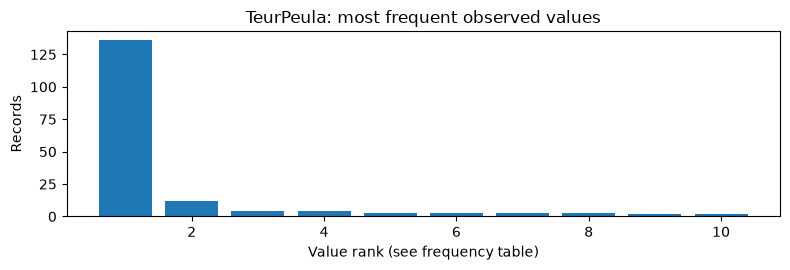

Task references: 12
Unresolved repeated-answer task descriptions: 12 record(s)


,ID,EzoAvoda,TeurPeula
0,1,סגן מנהל אגף,"כנ""ל"
1,2,טכנאית רדיותרפיה,"כנ""ל"
11,12,"טיפול בלקוחות עסקיים של הבנק, בדיקות לצורך מתן הלוואות","כנ""ל"
31,32,סגן מנהל אגף,"כנ""ל"
32,33,טכנאית רדיותרפיה,"כנ""ל"
42,43,"טיפול בלקוחות עסקיים של הבנק, בדיקות לצורך מתן הלוואות","כנ""ל"
63,64,מנהל אגף,"כנ""ל"
64,65,טכנאית רדיותרפיה,"כנ""ל"
74,75,"טיפול בלקוחות עסקיים של הבנק, בדיקות לצורך מתן הלוואות","כנ""ל"
94,95,סוקר,"כנ""ל"


OBSERVATION VS. INTERPRETATION: Task details can discriminate similar titles, but references such as כנ״ל need context.
DATA-PROCESSING DECISION: Preserve tasks independently and flag unresolved references.


In [ ]:
# FIELD INVESTIGATION: TeurPeula — Performed actions and references
# Questions from the approved seven-slide presentation:
# Q1. מדוע נדרשות פעולות בנוסף לתיאור העבודה?
QUESTIONS = ["מדוע נדרשות פעולות בנוסף לתיאור העבודה?"]
v = inspect_source_field('TeurPeula', QUESTIONS, plot='category')
refs = v.fillna('').str.fullmatch(r'כנ["״]?ל')
print('Task references:', int(refs.sum()))
show_evidence(refs, ['EzoAvoda','TeurPeula'],
              'Unresolved repeated-answer task descriptions')
print('OBSERVATION VS. INTERPRETATION: Task details can discriminate similar titles, but references such as כנ״ל need context.')
print('DATA-PROCESSING DECISION: Preserve tasks independently and flag unresolved references.')


### TeurTafkid — Optional title
**Questions:** האם לכל עובד יש תואר משרה? · האם תואר שווה לתוכן העבודה?

**Hypothesis and competing interpretation:** The metadata defines a job title as conditional on existence; zero is not intrinsically a title.

**Decision subject to observed evidence:** Retain valid titles as independent evidence; flag missing/placeholder states.

The next Python cell contains these exact questions and computes the evidence against the workbook.



FIELD: TeurTafkid
RESEARCH QUESTIONS:
Q1. האם לכל עובד יש תואר משרה?
Q2. האם תואר שווה לתוכן העבודה?
Observed: present=28, missing=172, distinct=16; records=200
Slide counts: present=28, distinct=16; verified=True
METADATA: field definition and source type


,משתנה,הסבר,פורמט,ערכים אפשריים
8,TeurTafkid,מהו תואר המשרה של הנסקר במקום עבודה זה (במידה ויש),TEXT,nan


ACTUAL RESPONSE FREQUENCIES:


,records
source_value,
,172
כלכלן,6
"כנ""ל",4
סגן מנהל אגף,3
טכנאי מחשבים,3
0,1
בונה מודלים של AI,1
סוקר,1
פיתוח תכנה,1


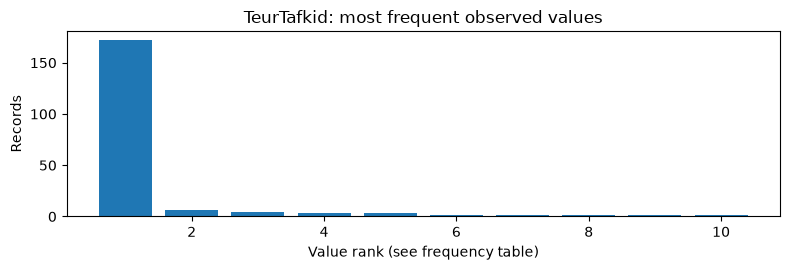

Possible numeric or textual job-title placeholders: 5 record(s)


,ID,TeurTafkid,EzoAvoda
1,2,"כנ""ל",טכנאית רדיותרפיה
32,33,"כנ""ל",טכנאית רדיותרפיה
38,39,0,"מהנדס תוכנה, מנהל צוות פיתוח"
64,65,"כנ""ל",טכנאית רדיותרפיה
95,96,"כנ""ל",טכנאית רדיותרפיה


Missing title is not proof that no job title exists.
OBSERVATION VS. INTERPRETATION: The metadata defines a job title as conditional on existence; zero is not intrinsically a title.
DATA-PROCESSING DECISION: Retain valid titles as independent evidence; flag missing/placeholder states.


In [ ]:
# FIELD INVESTIGATION: TeurTafkid — Optional title
# Questions from the approved seven-slide presentation:
# Q1. האם לכל עובד יש תואר משרה?
# Q2. האם תואר שווה לתוכן העבודה?
QUESTIONS = ["האם לכל עובד יש תואר משרה?","האם תואר שווה לתוכן העבודה?"]
v = inspect_source_field('TeurTafkid', QUESTIONS, plot='category')
placeholder = v.fillna('').str.fullmatch(r'0|אין|כנ["״]?ל')
show_evidence(placeholder, ['TeurTafkid','EzoAvoda'],
              'Possible numeric or textual job-title placeholders')
print('Missing title is not proof that no job title exists.')
print('OBSERVATION VS. INTERPRETATION: The metadata defines a job title as conditional on existence; zero is not intrinsically a title.')
print('DATA-PROCESSING DECISION: Retain valid titles as independent evidence; flag missing/placeholder states.')


### MenahelEtMi — Management role
**Questions:** מה פירוש 1, 2 ו־3? · האם הם מסודרים כרמות ניהול? · מדוע להוסיף אפס לריקים? · למה לא לבצע One Hot? · האם 1.725 הוא ערך בסקר?

**Hypothesis and competing interpretation:** Codes 1, 2 and 3 denote managing employees, managers, or both; blank does not directly mean zero.

**Decision subject to observed evidence:** Preserve nominal role and missingness; test zero-as-no-management only as a stated assumption.

The next Python cell contains these exact questions and computes the evidence against the workbook.



FIELD: MenahelEtMi
RESEARCH QUESTIONS:
Q1. מה פירוש 1, 2 ו־3?
Q2. האם הם מסודרים כרמות ניהול?
Q3. מדוע להוסיף אפס לריקים?
Q4. למה לא לבצע One Hot?
Q5. האם 1.725 הוא ערך בסקר?
Observed: present=32, missing=168, distinct=3; records=200
Slide counts: present=32, distinct=None; verified=True
METADATA: field definition and source type


,משתנה,הסבר,פורמט,ערכים אפשריים
9,MenahelEtMi,האם הנסקר מנהל או ממונה על עובדים אחרים?,INTEGER,1. מנהל עובדים 2. מנהל מנהלים 3. מנהל עובדים ומנהלים


ACTUAL RESPONSE FREQUENCIES:


,records
source_value,
,168
3,13
2,11
1,8


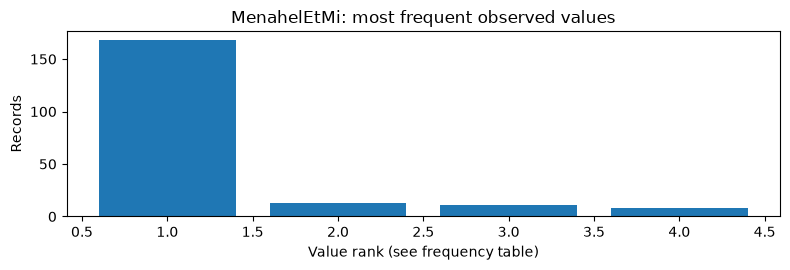

Defined meanings: 1=employees, 2=managers, 3=both
Management codes outside the metadata definitions: 0 record(s)
Missing management responses: 168
Hypothetical zero-coded values: 168
Observed 1.725 among keyed responses: 0
INFERENCE: management role is not a verified uniform numeric ranking.
OBSERVATION VS. INTERPRETATION: Codes 1, 2 and 3 denote managing employees, managers, or both; blank does not directly mean zero.
DATA-PROCESSING DECISION: Preserve nominal role and missingness; test zero-as-no-management only as a stated assumption.


In [ ]:
# FIELD INVESTIGATION: MenahelEtMi — Management role
# Questions from the approved seven-slide presentation:
# Q1. מה פירוש 1, 2 ו־3?
# Q2. האם הם מסודרים כרמות ניהול?
# Q3. מדוע להוסיף אפס לריקים?
# Q4. למה לא לבצע One Hot?
# Q5. האם 1.725 הוא ערך בסקר?
QUESTIONS = ["מה פירוש 1, 2 ו־3?","האם הם מסודרים כרמות ניהול?","מדוע להוסיף אפס לריקים?","למה לא לבצע One Hot?","האם 1.725 הוא ערך בסקר?"]
v = inspect_source_field('MenahelEtMi', QUESTIONS, plot='category')
print('Defined meanings: 1=employees, 2=managers, 3=both')
show_evidence(v.notna() & ~v.isin(['1','2','3']), ['MenahelEtMi'],
              'Management codes outside the metadata definitions')
print('Missing management responses:', int(v.isna().sum()))
zero_if_assumed = v.fillna('0')
print('Hypothetical zero-coded values:', int(zero_if_assumed.eq('0').sum()))
print('Observed 1.725 among keyed responses:', int(v.eq('1.725').sum()))
print('INFERENCE: management role is not a verified uniform numeric ranking.')
print('OBSERVATION VS. INTERPRETATION: Codes 1, 2 and 3 denote managing employees, managers, or both; blank does not directly mean zero.')
print('DATA-PROCESSING DECISION: Preserve nominal role and missingness; test zero-as-no-management only as a stated assumption.')


### MaamadAvoda — Employment status
**Questions:** מה משמעות הקודים 1 עד 7? · האם הם מציינים דירוג או סוג העסקה? · מדוע לא להשאיר אותם כמספר?

**Hypothesis and competing interpretation:** Codes identify seven forms of employment, not a single ordinal scale.

**Decision subject to observed evidence:** One-hot encode status categories when fitting training folds; code 1/5 determines salary-source eligibility.

The next Python cell contains these exact questions and computes the evidence against the workbook.



FIELD: MaamadAvoda
RESEARCH QUESTIONS:
Q1. מה משמעות הקודים 1 עד 7?
Q2. האם הם מציינים דירוג או סוג העסקה?
Q3. מדוע לא להשאיר אותם כמספר?
Observed: present=198, missing=2, distinct=4; records=200
METADATA: field definition and source type


,משתנה,הסבר,פורמט,ערכים אפשריים
10,MaamadAvoda,מעמד הנסקר במקום עבודה זה,INTEGER,"1. שכיר (כולל שכיר בעל חברת בע""מ) 2. עצמאי שמעסיק 1-2 עובדים 3. עצמאי שמעסיק 3 עובדים ויותר 4. עצמאי שלא מעסיק עובדים 5. חבר קואופרטיב 6. חבר קיבוץ 7. בן משפחה העובד ללא תשלום"


ACTUAL RESPONSE FREQUENCIES:


,records
source_value,
1,177
4,10
6,10
,2
2,1


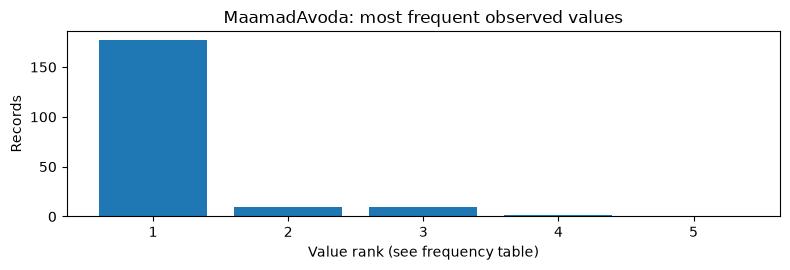

Metadata-grounded categories:


1                      employee
2    self-employed, 1–2 workers
3     self-employed, 3+ workers
4     self-employed, no workers
5            cooperative member
6                kibbutz member
7                 unpaid family
Name: status_meaning, dtype: object

Employment codes outside the seven documented categories: 0 record(s)
NEXT QUESTION: does MakorSachar obey the eligibility rule for codes 1 and 5?
OBSERVATION VS. INTERPRETATION: Codes identify seven forms of employment, not a single ordinal scale.
DATA-PROCESSING DECISION: One-hot encode status categories when fitting training folds; code 1/5 determines salary-source eligibility.


In [ ]:
# FIELD INVESTIGATION: MaamadAvoda — Employment status
# Questions from the approved seven-slide presentation:
# Q1. מה משמעות הקודים 1 עד 7?
# Q2. האם הם מציינים דירוג או סוג העסקה?
# Q3. מדוע לא להשאיר אותם כמספר?
QUESTIONS = ["מה משמעות הקודים 1 עד 7?","האם הם מציינים דירוג או סוג העסקה?","מדוע לא להשאיר אותם כמספר?"]
v = inspect_source_field('MaamadAvoda', QUESTIONS, plot='category')
meaning = {'1':'employee','2':'self-employed, 1–2 workers',
           '3':'self-employed, 3+ workers','4':'self-employed, no workers',
           '5':'cooperative member','6':'kibbutz member','7':'unpaid family'}
print('Metadata-grounded categories:'); display(pd.Series(meaning, name='status_meaning'))
show_evidence(v.notna() & ~v.isin(list(meaning)), ['MaamadAvoda'],
              'Employment codes outside the seven documented categories')
print('NEXT QUESTION: does MakorSachar obey the eligibility rule for codes 1 and 5?')
print('OBSERVATION VS. INTERPRETATION: Codes identify seven forms of employment, not a single ordinal scale.')
print('DATA-PROCESSING DECISION: One-hot encode status categories when fitting training folds; code 1/5 determines salary-source eligibility.')


### MakorSachar — salary source, conditional on MaamadAvoda

**Questions from the approved presentation:** למי מיועדת שאלת מקור השכר? האם 1 עד 4 מציינים מדרג? מה משמעות תשובה של מי שאינו זכאי?

The already-inserted salary analysis code immediately below checks the two fields together. It displays the code dictionary, observed response-state counts, crosstabulation, conflicting ID-linked records, a chart, and an evidence-based conclusion. That original example cell is preserved unchanged.


RESEARCH QUESTIONS
1. למי מיועדת שאלת מקור השכר?
2. האם 1 עד 4 מציינים מדרג?
3. מה משמעות תשובה של מי שאינו זכאי?

SOURCE METADATA: employment status and salary source


,משתנה,הסבר,פורמט,ערכים אפשריים
10,MaamadAvoda,מעמד הנסקר במקום עבודה זה,INTEGER,"1. שכיר (כולל שכיר בעל חברת בע""מ) 2. עצמאי שמעסיק 1-2 עובדים 3. עצמאי שמעסיק 3 עובדים ויותר 4. עצמאי שלא מעסיק עובדים 5. חבר קואופרטיב 6. חבר קיבוץ 7. בן משפחה העובד ללא תשלום"
11,MakorSachar,מקור השכר של הנסקר (השדה מלא רק במידה והנסקר שכיר או חבר קואופרטיב - כפי שצויין בשדה :MaamadAvoda ),INTEGER,"1. מקום העבודה 2. מחברת קבלן: בית תוכנה, חברת שמירה, ניקיון וכדומה 3. מחברת כוח אדם 4. אחר"



QUESTION 2 — Codes 1–4 are alternative sources, not an ordinal scale:


,MakorSachar,Meaning_from_presentation
0,1,Paid by employer
1,2,Paid by contractor
2,3,Paid by staffing agency
3,4,Other salary source



OBSERVED RESPONSE STATES (calculated, not copied from slides)


,response_state,records,salary_answers
0,eligible_answered,177,177
2,ineligible_blank_EXPECTED,12,0
1,ineligible_answered_CONFLICT,9,9
3,unknown_eligibility,2,0


... (2 outputs left out)


INELIGIBLE BUT ANSWERED: 9 source records


,ID,MaamadAvoda,MakorSachar,response_state
33,34,4,4,ineligible_answered_CONFLICT
48,49,4,1,ineligible_answered_CONFLICT
111,112,4,1,ineligible_answered_CONFLICT
139,140,4,1,ineligible_answered_CONFLICT
165,166,4,1,ineligible_answered_CONFLICT
175,176,4,1,ineligible_answered_CONFLICT
186,187,4,1,ineligible_answered_CONFLICT
189,190,2,1,ineligible_answered_CONFLICT
197,198,4,1,ineligible_answered_CONFLICT



ELIGIBLE BUT UNANSWERED: 0 source records

UNDEFINED SALARY-SOURCE CODE: 0 source records

UNKNOWN ELIGIBILITY: 2 source records


,ID,MaamadAvoda,MakorSachar,response_state
44,45,,,unknown_eligibility
107,108,,,unknown_eligibility


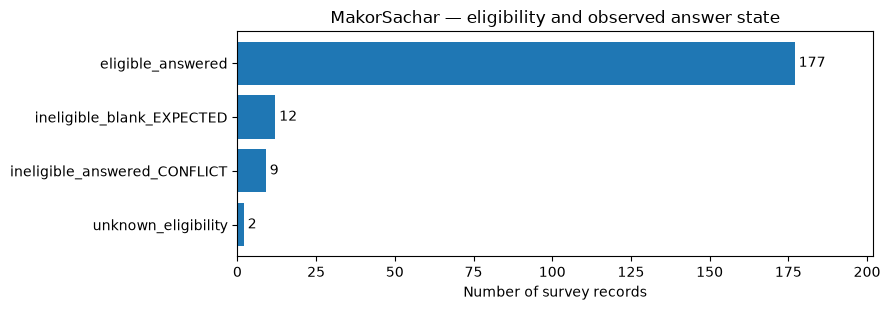


EVIDENCE-BASED CONCLUSIONS
Q1. Eligibility depends on MaamadAvoda = 1 or 5 (source rule).
Q2. Codes 1–4 represent nominal payment-source categories.
Q3. 9 ineligible records nevertheless provide an answer; their IDs are shown above for review.
Additional evidence: 0 eligible records leave the answer blank; 2 have unknown eligibility.
DECISION: keep source values; distinguish not-applicable, missing, contradictory and unknown states instead of treating all blanks alike.
NEXT QUESTION: Which inconsistencies need manual review before any feature encoding or imputation is fitted in a training fold?


In [ ]:
# INVESTIGATION 01 | Salary-source eligibility: one question, two related fields.
# Source: approved seven-slide presentation; original survey + metadata.
#
# RESEARCH QUESTIONS (verbatim):
# 1. למי מיועדת שאלת מקור השכר?
# 2. האם 1 עד 4 מציינים מדרג?
# 3. מה משמעות תשובה של מי שאינו זכאי?
#
# HYPOTHESES TO TEST:
# - Only employment statuses 1 (employee) and 5 (cooperative member) are eligible.
# - Salary-source codes 1–4 denote different categories, not ordered levels.
# - A blank from an ineligible respondent differs from a missing eligible answer.
# - An answer from an ineligible respondent is an inconsistency to investigate.
#
# All evidence is computed from the 200 original records; no source cells change.

salary_questions = [
    "למי מיועדת שאלת מקור השכר?",
    "האם 1 עד 4 מציינים מדרג?",
    "מה משמעות תשובה של מי שאינו זכאי?",
]
print("RESEARCH QUESTIONS")
for index, question in enumerate(salary_questions, start=1):
    print(f"{index}. {question}")

# A. Investigate the exact definitions instead of interpreting codes by magnitude.
salary_fields = ["MaamadAvoda", "MakorSachar"]
assert set(salary_fields).issubset(original.columns)
metadata_key = metadata.columns[0]
salary_definitions = metadata.loc[
    metadata[metadata_key].astype("string").str.strip().isin(salary_fields)
].copy()
assert len(salary_definitions) == 2, "Expected one metadata definition per field"
print("\nSOURCE METADATA: employment status and salary source")
display(salary_definitions)

salary_source_categories = pd.DataFrame({
    "MakorSachar": ["1", "2", "3", "4"],
    "Meaning_from_presentation": [
        "Paid by employer",
        "Paid by contractor",
        "Paid by staffing agency",
        "Other salary source",
    ],
})
print("\nQUESTION 2 — Codes 1–4 are alternative sources, not an ordinal scale:")
display(salary_source_categories)

# B. Preserve row identity and original values. Normalize a COPY for checking only.
salary_audit = original[["ID", *salary_fields]].copy()
for field in salary_fields:
    salary_audit[field] = (
        salary_audit[field].astype("string").str.strip().replace("", pd.NA)
    )

salary_status = salary_audit["MaamadAvoda"]
salary_value = salary_audit["MakorSachar"]
defined_status = salary_status.isin([str(i) for i in range(1, 8)])
eligible = salary_status.isin(["1", "5"])
answered = salary_value.notna()
valid_salary_code = salary_value.isin(["1", "2", "3", "4"])

# C. Answer Q1 and Q3 by evaluating eligibility AND actual response jointly.
salary_audit["response_state"] = np.select(
    [
        ~defined_status,
        eligible & answered,
        eligible & ~answered,
        defined_status & ~eligible & answered,
        defined_status & ~eligible & ~answered,
    ],
    [
        "unknown_eligibility",
        "eligible_answered",
        "eligible_missing",
        "ineligible_answered_CONFLICT",
        "ineligible_blank_EXPECTED",
    ],
    default="UNCLASSIFIED",
)
assert (salary_audit["response_state"] != "UNCLASSIFIED").all()
assert len(salary_audit) == len(original)
salary_audit["invalid_salary_code"] = answered & ~valid_salary_code

summary = (
    salary_audit.groupby("response_state", dropna=False)
    .agg(records=("ID", "size"), salary_answers=("MakorSachar", "count"))
    .reset_index().sort_values("records", ascending=False)
)
print("\nOBSERVED RESPONSE STATES (calculated, not copied from slides)")
display(summary)

print("\nCROSS-TABULATION — employment status vs. source code")
display(pd.crosstab(
    salary_status.fillna("<MISSING>"),
    salary_value.fillna("<MISSING>"),
    rownames=["MaamadAvoda"], colnames=["MakorSachar"],
    dropna=False,
))

# D. The analytical findings remain traceable to individual questionnaire IDs.
conflicts = salary_audit.loc[
    salary_audit["response_state"].eq("ineligible_answered_CONFLICT")
]
missing_when_eligible = salary_audit.loc[
    salary_audit["response_state"].eq("eligible_missing")
]
undefined_codes = salary_audit.loc[salary_audit["invalid_salary_code"]]
unknown_status = salary_audit.loc[
    salary_audit["response_state"].eq("unknown_eligibility")
]
for title, subset in [
    ("INELIGIBLE BUT ANSWERED", conflicts),
    ("ELIGIBLE BUT UNANSWERED", missing_when_eligible),
    ("UNDEFINED SALARY-SOURCE CODE", undefined_codes),
    ("UNKNOWN ELIGIBILITY", unknown_status),
]:
    print(f"\n{title}: {len(subset)} source records")
    if not subset.empty:
        display(subset[["ID", "MaamadAvoda", "MakorSachar", "response_state"]])

# E. Visualization is derived exclusively from measured response counts.
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(summary["response_state"], summary["records"])
ax.set(xlabel="Number of survey records",
       title="MakorSachar — eligibility and observed answer state")
ax.invert_yaxis()
for y, count in enumerate(summary["records"]):
    ax.text(count, y, f" {count}", va="center")
ax.set_xlim(0, max(summary["records"].max() * 1.14, 1))
plt.tight_layout()
plt.show()

# F. Answer all questions; distinguish measured findings from assumptions.
print("\nEVIDENCE-BASED CONCLUSIONS")
print("Q1. Eligibility depends on MaamadAvoda = 1 or 5 (source rule).")
print("Q2. Codes 1–4 represent nominal payment-source categories.")
print(f"Q3. {len(conflicts)} ineligible records nevertheless provide an answer; "
      "their IDs are shown above for review.")
print(f"Additional evidence: {len(missing_when_eligible)} eligible records "
      f"leave the answer blank; {len(unknown_status)} have unknown eligibility.")
print("DECISION: keep source values; distinguish not-applicable, missing, "
      "contradictory and unknown states instead of treating all blanks alike.")
print("NEXT QUESTION: Which inconsistencies need manual review before "
      "any feature encoding or imputation is fitted in a training fold?")

### TeudaGvoha — Educational certificate categories
**Questions:** האם קוד גבוה פירושו השכלה גבוהה יותר? · מה משמעות הקודים 8 ו־9? · האם קיים סדר אחיד לכל הקטגוריות?

**Hypothesis and competing interpretation:** Code 8 is other and 9 is no certificate; therefore nine categories are not a monotone scale.

**Decision subject to observed evidence:** Preserve separate nominal certificate categories rather than numerical magnitude.

The next Python cell contains these exact questions and computes the evidence against the workbook.



FIELD: TeudaGvoha
RESEARCH QUESTIONS:
Q1. האם קוד גבוה פירושו השכלה גבוהה יותר?
Q2. מה משמעות הקודים 8 ו־9?
Q3. האם קיים סדר אחיד לכל הקטגוריות?
Observed: present=198, missing=2, distinct=7; records=200
METADATA: field definition and source type


,משתנה,הסבר,פורמט,ערכים אפשריים
12,TeudaGvoha,התעודה או התואר הגבוה ביותר של הנסקר,INTEGER,"1. תעוד סיום של בי""ס יסודי או חטיבת ביניים 2. תעודת סיום תיכון שאינה תעודת בגרות 3. תעודת בגרות 4. תעודת סיום של בי""ס על תיכוני שאינה תעודה אקדמית 5. תואר אקדמי ראשון B.A, או תואר מקביל 6. תואר אקדמי שני M.A, או תואר מקביל כולל דוקטור לרפואה 7. תואר אקדמי שלישי Ph.D, או תואר מקביל 8. תעודה אחרת, ציין 9. לא קיבל אף תעודה"


ACTUAL RESPONSE FREQUENCIES:


,records
source_value,
4,58
3,57
6,39
5,25
2,12
7,4
1,3
,2


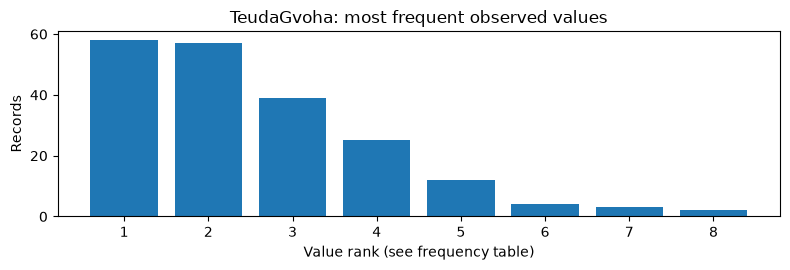

Education code 8 = other certificate; 9 = no certificate.
Undefined educational certificate codes: 0 record(s)
INFERENCE: one-hot encoding is more defensible than raw 1..9 ordering.
OBSERVATION VS. INTERPRETATION: Code 8 is other and 9 is no certificate; therefore nine categories are not a monotone scale.
DATA-PROCESSING DECISION: Preserve separate nominal certificate categories rather than numerical magnitude.


In [ ]:
# FIELD INVESTIGATION: TeudaGvoha — Educational certificate categories
# Questions from the approved seven-slide presentation:
# Q1. האם קוד גבוה פירושו השכלה גבוהה יותר?
# Q2. מה משמעות הקודים 8 ו־9?
# Q3. האם קיים סדר אחיד לכל הקטגוריות?
QUESTIONS = ["האם קוד גבוה פירושו השכלה גבוהה יותר?","מה משמעות הקודים 8 ו־9?","האם קיים סדר אחיד לכל הקטגוריות?"]
v = inspect_source_field('TeudaGvoha', QUESTIONS, plot='category')
print('Education code 8 = other certificate; 9 = no certificate.')
show_evidence(v.notna() & ~v.isin(list('123456789')),
              ['TeudaGvoha'], 'Undefined educational certificate codes')
print('INFERENCE: one-hot encoding is more defensible than raw 1..9 ordering.')
print('OBSERVATION VS. INTERPRETATION: Code 8 is other and 9 is no certificate; therefore nine categories are not a monotone scale.')
print('DATA-PROCESSING DECISION: Preserve separate nominal certificate categories rather than numerical magnitude.')


### shnotlimud — Years of schooling
**Questions:** האם זה קוד או מספר שנות לימוד? · מה הופך ערך לבלתי תקין?

**Hypothesis and competing interpretation:** Years of schooling is a count; unlike qualification codes it is quantitatively meaningful.

**Decision subject to observed evidence:** Parse/check numeric years; impute only in model-training folds.

The next Python cell contains these exact questions and computes the evidence against the workbook.



FIELD: shnotlimud
RESEARCH QUESTIONS:
Q1. האם זה קוד או מספר שנות לימוד?
Q2. מה הופך ערך לבלתי תקין?
Observed: present=198, missing=2, distinct=13; records=200
Slide counts: present=198, distinct=13; verified=True
METADATA: field definition and source type


,משתנה,הסבר,פורמט,ערכים אפשריים
13,shnotlimud,שנות הלימוד של הנסקר,INTEGER,nan


ACTUAL RESPONSE FREQUENCIES:


,records
source_value,
12,53
15,30
13,25
14,24
18,16
16,11
17,10
22,8
20,7


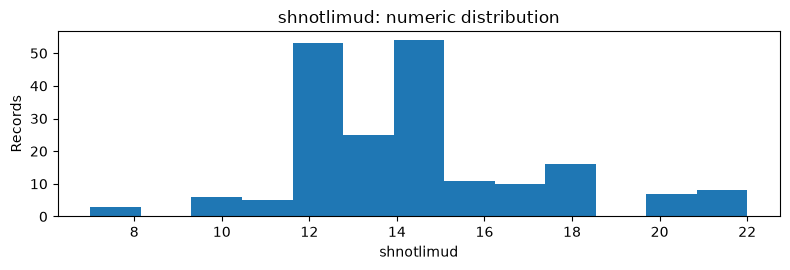

Non-numeric, negative or fractional schooling years: 0 record(s)
Observed schooling range: 7 22
No whole-dataset imputer is fitted here.
OBSERVATION VS. INTERPRETATION: Years of schooling is a count; unlike qualification codes it is quantitatively meaningful.
DATA-PROCESSING DECISION: Parse/check numeric years; impute only in model-training folds.


In [ ]:
# FIELD INVESTIGATION: shnotlimud — Years of schooling
# Questions from the approved seven-slide presentation:
# Q1. האם זה קוד או מספר שנות לימוד?
# Q2. מה הופך ערך לבלתי תקין?
QUESTIONS = ["האם זה קוד או מספר שנות לימוד?","מה הופך ערך לבלתי תקין?"]
v = inspect_source_field('shnotlimud', QUESTIONS, plot='numeric')
number = pd.to_numeric(v, errors='coerce')
bad = v.notna() & (number.isna() | number.lt(0) | number.mod(1).ne(0))
show_evidence(bad, ['shnotlimud'], 'Non-numeric, negative or fractional schooling years')
print('Observed schooling range:', number.min(), number.max())
print('No whole-dataset imputer is fitted here.')
print('OBSERVATION VS. INTERPRETATION: Years of schooling is a count; unlike qualification codes it is quantitatively meaningful.')
print('DATA-PROCESSING DECISION: Parse/check numeric years; impute only in model-training folds.')


### Gil — Age and reference date
**Questions:** גיל באיזה מועד? · האם ניתן לחשב אותו מחדש?

**Hypothesis and competing interpretation:** Observed age has no individual survey reference date; today's date cannot reconstruct historical age.

**Decision subject to observed evidence:** Preserve original age and investigate implausible values without fabricating observation dates.

The next Python cell contains these exact questions and computes the evidence against the workbook.



FIELD: Gil
RESEARCH QUESTIONS:
Q1. גיל באיזה מועד?
Q2. האם ניתן לחשב אותו מחדש?
Observed: present=198, missing=2, distinct=29; records=200
Slide counts: present=198, distinct=29; verified=True
METADATA: field definition and source type


,משתנה,הסבר,פורמט,ערכים אפשריים
14,Gil,גיל הנסקר,INTEGER,nan


ACTUAL RESPONSE FREQUENCIES:


,records
source_value,
25,16
55,15
31,15
32,15
35,14
42,10
44,10
48,8
46,8


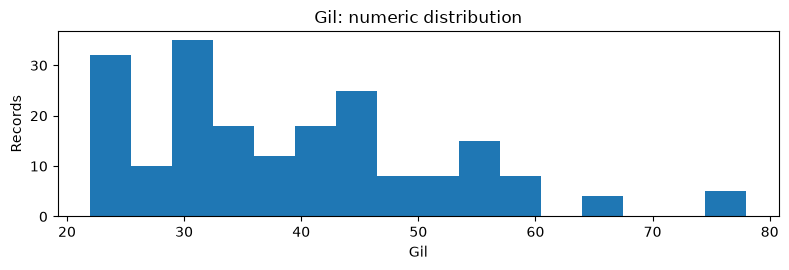

Age values needing review: 0 record(s)
Observed ages: 22 through 78
INFERENCE: current date is not a valid survey-age reference date.
OBSERVATION VS. INTERPRETATION: Observed age has no individual survey reference date; today's date cannot reconstruct historical age.
DATA-PROCESSING DECISION: Preserve original age and investigate implausible values without fabricating observation dates.


In [ ]:
# FIELD INVESTIGATION: Gil — Age and reference date
# Questions from the approved seven-slide presentation:
# Q1. גיל באיזה מועד?
# Q2. האם ניתן לחשב אותו מחדש?
QUESTIONS = ["גיל באיזה מועד?","האם ניתן לחשב אותו מחדש?"]
v = inspect_source_field('Gil', QUESTIONS, plot='numeric')
number = pd.to_numeric(v, errors='coerce')
review = v.notna() & (number.isna() | number.lt(0) | number.gt(120) | number.mod(1).ne(0))
show_evidence(review, ['Gil'], 'Age values needing review')
print('Observed ages:', number.min(), 'through', number.max())
print('INFERENCE: current date is not a valid survey-age reference date.')
print('OBSERVATION VS. INTERPRETATION: Observed age has no individual survey reference date; today\'s date cannot reconstruct historical age.')
print('DATA-PROCESSING DECISION: Preserve original age and investigate implausible values without fabricating observation dates.')


### SemelAnafSofi — Industry code representation and availability
**Questions:** האם ארבע ספרות הן מספר או קוד סיווג? · האם הקוד זמין בזמן החיזוי?

**Hypothesis and competing interpretation:** Industry labels are structured codes; Excel number formatting may hide leading zeros, and availability at prediction time is unknown.

**Decision subject to observed evidence:** Preserve code identity and partial values; evaluate use as a separate feature-availability scenario.

The next Python cell contains these exact questions and computes the evidence against the workbook.



FIELD: SemelAnafSofi
RESEARCH QUESTIONS:
Q1. האם ארבע ספרות הן מספר או קוד סיווג?
Q2. האם הקוד זמין בזמן החיזוי?
Observed: present=200, missing=0, distinct=44; records=200
Slide counts: present=200, distinct=44; verified=True
METADATA: field definition and source type


,משתנה,הסבר,פורמט,ערכים אפשריים
15,SemelAnafSofi,סמל ענף כלכלי של מקום העבודה - מורכב מ-4 ספרות לפי תקן בינלאומי,TEXT,nan


ACTUAL RESPONSE FREQUENCIES:


,records
source_value,
5610,14
6201,12
8411,11
6419,11
5510,9
4711,8
4772,8
4770,8
8010,7


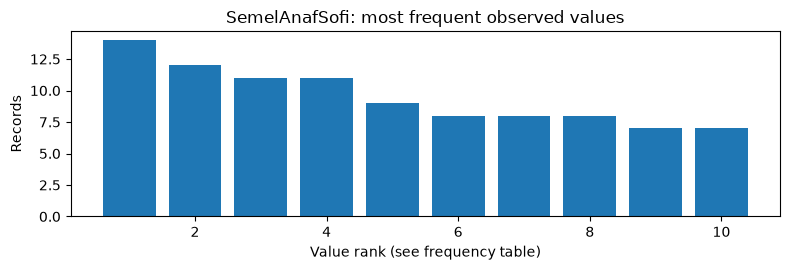

Short stored numeric values: 5
X-containing partial values: 9
Industry codes requiring inspection of four-digit Excel display format: 14 record(s)


,ID,SemelAnafSofi
4,5,XXXX
29,30,123
35,36,XXXX
61,62,123
67,68,XXXX
92,93,123
98,99,XXXX
124,125,123
127,128,XXXX
150,151,124


Do not label numeric 123 invalid if Excel displays it as 0123.
Industry code is not guaranteed available when predicting a person occupation.
OBSERVATION VS. INTERPRETATION: Industry labels are structured codes; Excel number formatting may hide leading zeros, and availability at prediction time is unknown.
DATA-PROCESSING DECISION: Preserve code identity and partial values; evaluate use as a separate feature-availability scenario.


In [ ]:
# FIELD INVESTIGATION: SemelAnafSofi — Industry code representation and availability
# Questions from the approved seven-slide presentation:
# Q1. האם ארבע ספרות הן מספר או קוד סיווג?
# Q2. האם הקוד זמין בזמן החיזוי?
QUESTIONS = ["האם ארבע ספרות הן מספר או קוד סיווג?","האם הקוד זמין בזמן החיזוי?"]
v = inspect_source_field('SemelAnafSofi', QUESTIONS, plot='category')
short = v.fillna('').str.fullmatch(r'\d{1,3}')
partial = v.fillna('').str.contains('X', case=False, regex=False)
print('Short stored numeric values:', int(short.sum()))
print('X-containing partial values:', int(partial.sum()))
show_evidence(short | partial, ['SemelAnafSofi'],
              'Industry codes requiring inspection of four-digit Excel display format')
print('Do not label numeric 123 invalid if Excel displays it as 0123.')
print('Industry code is not guaranteed available when predicting a person occupation.')
print('OBSERVATION VS. INTERPRETATION: Industry labels are structured codes; Excel number formatting may hide leading zeros, and availability at prediction time is unknown.')
print('DATA-PROCESSING DECISION: Preserve code identity and partial values; evaluate use as a separate feature-availability scenario.')


### TarichHathala — Job-start date
**Questions:** התחלה של מה? · עד איזה מועד מחשבים ותק?

**Hypothesis and competing interpretation:** Start date is not tenure without an observation-time reference.

**Decision subject to observed evidence:** Parse recorded dates; do not subtract from the present date to invent tenure.

The next Python cell contains these exact questions and computes the evidence against the workbook.


In [ ]:
# FIELD INVESTIGATION: TarichHathala — Job-start date
# Questions from the approved seven-slide presentation:
# Q1. התחלה של מה?
# Q2. עד איזה מועד מחשבים ותק?
QUESTIONS = ["התחלה של מה?","עד איזה מועד מחשבים ותק?"]
v = inspect_source_field('TarichHathala', QUESTIONS, plot='none')
parsed = pd.to_datetime(v, dayfirst=True, errors='coerce')
show_evidence(v.notna() & parsed.isna(),
              ['TarichHathala'], 'Job-start dates that fail parsing')
print('Earliest parsed:', parsed.min(), '| latest parsed:', parsed.max())
display(parsed.dt.year.value_counts().sort_index().rename_axis('year').to_frame('records'))
print('Tenure cannot be computed from this field alone.')
print('OBSERVATION VS. INTERPRETATION: Start date is not tenure without an observation-time reference.')
print('DATA-PROCESSING DECISION: Parse recorded dates; do not subtract from the present date to invent tenure.')


### SemelMishlachSofi — Occupational target
**Questions:** מהו יעד החיזוי? · כיצד מתייחסים לקוד חלקי ולשגיאות סמלנים?

**Hypothesis and competing interpretation:** Manually coded occupation is a structured categorical target; X preserves incomplete prefix information.

**Decision subject to observed evidence:** Evaluate full four-digit codes separately; preserve partial patterns and acknowledge uncertain label correctness.

The next Python cell contains these exact questions and computes the evidence against the workbook.


In [ ]:
# FIELD INVESTIGATION: SemelMishlachSofi — Occupational target
# Questions from the approved seven-slide presentation:
# Q1. מהו יעד החיזוי?
# Q2. כיצד מתייחסים לקוד חלקי ולשגיאות סמלנים?
QUESTIONS = ["מהו יעד החיזוי?","כיצד מתייחסים לקוד חלקי ולשגיאות סמלנים?"]
v = inspect_source_field('SemelMishlachSofi', QUESTIONS, plot='category')
complete = v.fillna('').str.fullmatch(r'\d{4}')
partial = v.fillna('').str.fullmatch(r'[\dXx]{4}') & ~complete
print('Complete coded records:', int(complete.sum()))
print('Partial coded records:', int(partial.sum()))
print('Partial code types:'); display(v[partial].value_counts().to_frame('records'))
show_evidence(v.notna() & ~(complete | partial), ['SemelMishlachSofi'],
              'Occupation target formats needing manual review')
print('Approximate manual coding quality is not a verified row-level truth label.')
print('OBSERVATION VS. INTERPRETATION: Manually coded occupation is a structured categorical target; X preserves incomplete prefix information.')
print('DATA-PROCESSING DECISION: Evaluate full four-digit codes separately; preserve partial patterns and acknowledge uncertain label correctness.')


### Cross-field semantic question: seven free-text variables
**Questions from the approved presentation:** האם TEXT בהכרח שדה בחירה? למה לא Label Encoding או One Hot? איזו בעיה TF-IDF אינו פותר? באילו שדות קיימת באמת בעיית שתי שפות? האם LaBSE מתאים גם לתפקידים ולמשימות? מתי להמיר אותיות באנגלית לקטנות?

Compare Latin-script coverage, Hebrew text, mixed scripts, missingness and the relative-answer marker `כנ״ל` across the seven text fields, without changing source case. Check whether all 18 original survey columns have been investigated. Preserve descriptions as text rather than arbitrary numeric labels.


In [ ]:
# QUESTIONS (from presentation): Which seven fields are text? Which are multilingual?
# Does TF-IDF connect INTEL and אינטל? Can LaBSE address employer-name
# equivalence without falsely merging occupational duties or job titles?
seven_text = ['ShemAvoda','SugAvoda','ShemMachlaka','SugMachlaka',
              'EzoAvoda','TeurPeula','TeurTafkid']
language_evidence = []
for column in seven_text:
    value = original[column].fillna('').astype(str).str.strip()
    latin = value.str.contains(r'[A-Za-z]', regex=True)
    hebrew = value.str.contains(r'[\u0590-\u05FF]', regex=True)
    ref = value.str.fullmatch(r'כנ["״]?ל')
    language_evidence.append({
        'field': column, 'Latin_records': int(latin.sum()),
        'Hebrew_records': int(hebrew.sum()),
        'Mixed_script': int((latin & hebrew).sum()),
        'Relative_reference': int(ref.sum()),
        'Empty': int(value.eq('').sum()),
    })
display(pd.DataFrame(language_evidence))
missing_audits = set(original.columns) - (set(FIELD_AUDITS) | {'MakorSachar'})
assert not missing_audits, f'Original columns without investigation: {missing_audits}'
assert len(FIELD_AUDITS) == 17
print('All 18 survey fields investigated: 17 field-specific cells plus salary-source cross-field cell.')
print('DECISION: preserve raw case for LaBSE, lowercase only inside TF-IDF preprocessing;')
print('never apply employer-name equivalence mapping to tasks, roles or job titles.')


### Decisions

The field checks above establish the available evidence, missingness and inconsistencies. I use these results and the metadata definitions to determine which source values to retain, which cases require review, and which transformations are justified. I keep unverified assumptions separate from observed facts.


### Transformations

I preserve the original survey and create separate derived values where required. The following multilingual employer-name analysis is confined to the employer-name field; candidate matches remain distinguishable from verified identities.


### Load LaBSE for employer-name data investigation
**Question:** Can pretrained multilingual embeddings propose Hebrew equivalents for English employer-name expressions?

This is a **data-processing model**, not a library import and not the target occupation classifier. It follows the existing [LaBSE English–Hebrew project](https://github.com/shulruferor-sudo/Advance-Data-Science/blob/main/projects/LaBSE/labse_english_hebrew_only.ipynb). The model weights are downloaded and cached on first run; CPU inference needs no GPU or token.

**Scope:** compare English phrases only with existing Hebrew-only values of `ShemAvoda`. The approved presentation uses `cosine > α`; a similarity score is **not proof of the same legal employer**.


In [ ]:
# Data-processing question: load the pretrained LaBSE encoder, separate from imports.
import importlib.util
import subprocess
import sys
if importlib.util.find_spec('sentence_transformers') is None:
    subprocess.check_call([
        sys.executable, '-m', 'pip', 'install', '--quiet',
        'sentence-transformers==5.1.2',
    ])
from sentence_transformers import SentenceTransformer
labse_model = SentenceTransformer('sentence-transformers/LaBSE', device='cpu')
labse_model.eval()
print('LaBSE loaded on CPU for English–Hebrew employer-name candidate comparison.')


### LaBSE inference: candidate employer-name normalization (not automatic identity merging)
**Research questions:** How might `INTEL` correspond to `אינטל`? Which original Hebrew employer name is nearest to each English phrase? Is the presentation's `α=0.50` strong enough to support identity claims?

**Method:** derive candidate English phrases and Hebrew-only employer names solely from `ShemAvoda`; normalize the embedding vectors and calculate cosine scores; inspect the strongest match and the runner-up margin. Record a proposed replacement only where the score exceeds α, label the proposal for professional review, and preserve `original`.

**Conclusion boundary:** a candidate is not a verified organization match. `prepared_survey_labse` holds proposed values as additional **data preparation columns**, not authoritative replacements. The original classifier remains unchanged: using mappings as supervised features inside cross-validation would require learning the mapping independently in every training fold to prevent leakage.


In [ ]:
# QUESTIONS: Which Hebrew-only employer candidate most closely matches each Latin
# expression? Is cosine > alpha sufficient to establish employer identity?
# This cell generates auditable proposals; it does not overwrite source data.
LABSE_ALPHA = 0.50  # Fixed proposal threshold from the presentation; not validated precision.
LATIN = re.compile(r"[A-Za-z]+(?:[&./'-][A-Za-z]+)*(?:\s+[A-Za-z]+(?:[&./'-][A-Za-z]+)*)*")
HEBREW = re.compile(r'[\u0590-\u05FF]')
raw_employers = original['ShemAvoda'].fillna('').astype(str).str.strip()
english = sorted({m.group() for s in raw_employers for m in LATIN.finditer(s)})
hebrew = sorted({
    s for s in raw_employers if s and HEBREW.search(s) and not LATIN.search(s)
})
print('Latin expressions:', len(english), '| Hebrew-only employer strings:', len(hebrew))
proposals = []
candidate_lookup = {}
if english and hebrew:
    vectors = labse_model.encode(
        english + hebrew, batch_size=8, normalize_embeddings=True,
        convert_to_numpy=True, show_progress_bar=False,
    )
    cosine_matrix = vectors[:len(english)] @ vectors[len(english):].T
    for i, source_term in enumerate(english):
        ordered = np.argsort(-cosine_matrix[i])
        best = int(ordered[0])
        top_score = float(cosine_matrix[i, best])
        second_score = float(cosine_matrix[i, int(ordered[1])]) if len(ordered) > 1 else np.nan
        target = hebrew[best]
        above = top_score > LABSE_ALPHA
        proposals.append({
            'English': source_term, 'Hebrew_candidate': target,
            'top_cosine': top_score, 'runner_up_cosine': second_score,
            'margin': top_score - second_score, 'exceeds_alpha': above,
            'requires_human_verification': True,
        })
        if above:
            candidate_lookup[source_term] = target

labse_employer_proposals = pd.DataFrame(proposals)
if not labse_employer_proposals.empty:
    labse_employer_proposals = labse_employer_proposals.sort_values(
        'top_cosine', ascending=False
    )
display(labse_employer_proposals)

def proposed_employer_name(raw_name):
    """Candidate-only substitution: original source values are never edited."""
    return LATIN.sub(lambda m: candidate_lookup.get(m.group(), m.group()), raw_name)

prepared_survey_labse = original.copy(deep=True)
prepared_survey_labse['ShemAvoda_LaBSE_proposed'] = raw_employers.map(proposed_employer_name)
prepared_survey_labse['ShemAvoda_LaBSE_review'] = (
    prepared_survey_labse['ShemAvoda_LaBSE_proposed'] != raw_employers
)
labse_review = prepared_survey_labse.loc[
    prepared_survey_labse['ShemAvoda_LaBSE_review'],
    ['ID', 'ShemAvoda', 'ShemAvoda_LaBSE_proposed']
].copy()
print('Proposed substitutions requiring review:', len(labse_review))
display(labse_review)
assert original.shape == (200, 18)
assert original['ShemAvoda'].equals(data['ShemAvoda'])
print('Original 200 records and 18 fields preserved; existing prediction pipeline unchanged.')
print('NEXT QUESTION: validate true employer equivalence on independently labeled pairs,')
print('then test any predictive gains using fold-safe feature construction.')


## Classification and evaluation

The following stages construct and evaluate occupational predictors using the prepared evidence, while retaining the original source fields for comparison.


## Distinguishing sources of uncertainty

I distinguish three situations that have different implications for classification. A respondent may leave a question unanswered. The descriptions supplied across questions may disagree. A professional coder may assign only part of the occupational code. I examine these situations separately because a single missing value indicator would obscure their different meanings.

In [ ]:
TEXT=['YeshuvAvoda','ShemAvoda','SugAvoda','ShemMachlaka','SugMachlaka','EzoAvoda','TeurPeula','TeurTafkid']
OCC=['SugAvoda','ShemMachlaka','SugMachlaka','EzoAvoda','TeurPeula','TeurTafkid']
TARGET='SemelMishlachSofi'
def clean(x):
    if pd.isna(x):return ''
    return re.sub(r'\s+',' ',str(x).strip()).casefold()
def meaningful(x):return bool(clean(x)) and clean(x) not in {'כנ"ל','כנ״ל','כנל','חסוי','לא יכול לפרט'}
for c in TEXT:data[c+'_observed']=data[c].map(meaningful).astype(int)
data['occupation_evidence_count']=data[[c+'_observed' for c in OCC]].sum(axis=1)
data['target_resolution']=data[TARGET].fillna('').map(lambda x:sum(ch!='X' for ch in str(x)) if len(str(x))==4 else 0)
data['target_complete']=data[TARGET].fillna('').str.fullmatch(r'\d{4}').fillna(False)
display(data.groupby('occupation_evidence_count',dropna=False).agg(records=('ID','size'),fully_coded=('target_complete','sum'),mean_code_resolution=('target_resolution','mean')))
print('Records with incomplete occupational codes:',int((~data.target_complete).sum()))

,records,fully_coded,mean_code_resolution
occupation_evidence_count,,,
0,7,1,1.142857
1,16,16,4.000000
2,44,43,3.909091
3,50,49,3.920000
4,53,52,3.981132
5,20,20,4.000000
6,10,10,4.000000


Records with incomplete occupational codes: 9


## Administrative identity and occupational evidence

I treat `ID` as the record identifier rather than an occupational attribute. I compare substantive descriptions across records to identify repetition and conflicting classifications. A repeated description does not establish that two records belong to the same respondent. I therefore use occupational evidence signatures for analysis and grouping without using the record identifier as a predictor.

In [ ]:
def signature(row,cols):return ' | '.join(clean(row[c]) for c in cols)
data['evidence_signature']=data.apply(lambda r:signature(r,OCC),axis=1)
data['all_text_signature']=data.apply(lambda r:signature(r,TEXT),axis=1)
rep=data.groupby('evidence_signature').agg(n=('ID','size'),targets=(TARGET,lambda s:sorted(set(s.dropna()))),target_count=(TARGET,'nunique')).sort_values('n',ascending=False)
print('Description signatures shared by multiple records:',int((rep.n>1).sum()))
print('Description signatures associated with different occupational codes:',int(((rep.n>1)&(rep.target_count>1)).sum()))
display(rep[(rep.n>1)&(rep.target_count>1)].head(12))

Description signatures shared by multiple records: 49
Description signatures associated with different occupational codes: 3


,n,targets,target_count
evidence_signature,,,
"טיפול בחולים | רדיואתרפיה | טיפול בחולי סרטן | טכנאית רדיותרפיה | כנ""ל | כנ""ל",4,"[3211, 3311]",2
| | | | |,3,"[2511, XXXX]",2
"קבלת קהל | תמיכה בלקוחות | כנ""ל | קבלת קהל | קבלת קהל |",2,"[3354, 335X]",2


## Distinguishing occupational duties from workplace context

I separate descriptions of the respondent's duties from information about the employer and workplace. The same organization can employ people in different occupations, while similar duties can occur across different organizations. I measure the contribution of each information group through feature ablation rather than assuming that either group is sufficient on its own.

In [ ]:
ROLE=['EzoAvoda','TeurPeula','TeurTafkid','MenahelEtMi']
CONTEXT=['ShemAvoda','SugAvoda','ShemMachlaka','SugMachlaka','YeshuvAvoda']
OTHER=['MaamadAvoda','MakorSachar','TeudaGvoha','shnotlimud','Gil','TarichHathala']
def pack(frame,cols):
    return frame.apply(lambda r:' '.join(f'{c} {clean(r[c])}' for c in cols if meaningful(r[c])),axis=1)
for name,cols in [('role',ROLE),('context',CONTEXT),('combined',ROLE+CONTEXT+OTHER)]:data['text_'+name]=pack(data,cols)
valid=data.loc[data.target_complete].copy()
print('Records with complete occupational codes:',len(valid),'Distinct complete occupational codes:',valid[TARGET].nunique())
print('Most frequent complete occupational codes:');display(valid[TARGET].value_counts().head(12))

Records with complete occupational codes: 191 Distinct complete occupational codes: 59
Most frequent complete occupational codes:


,count
SemelMishlachSofi,
5223,14
9112,12
2512,10
5120,7
2511,7
5414,7
5412,7
5230,6
5322,6


## Evaluation across distinct occupational descriptions

I group records by their substantive occupational descriptions before cross validation so that identical descriptions do not appear in both training and test partitions. I compare a majority class baseline with independently trained text classifiers. I report held out performance together with the limitations created by rare occupational codes in this simulated sample.

In [ ]:
from sklearn.model_selection import GroupKFold
from sklearn.metrics import balanced_accuracy_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline
models={
 'Majority class baseline':DummyClassifier(strategy='most_frequent'),
 'Word TFIDF logistic regression':make_pipeline(TfidfVectorizer(analyzer='word',ngram_range=(1,2),min_df=1),LogisticRegression(max_iter=1500,class_weight='balanced',random_state=SEED)),
 'Character TFIDF support vector classifier':make_pipeline(TfidfVectorizer(analyzer='char',ngram_range=(2,5),min_df=1,max_features=25000),LinearSVC(class_weight='balanced',random_state=SEED)),
 'Character TFIDF naive Bayes':make_pipeline(TfidfVectorizer(analyzer='char',ngram_range=(2,4),min_df=1,max_features=25000),ComplementNB(alpha=0.5))}
groups=valid['evidence_signature']; folds=min(5,groups.nunique())
assert folds>=2
cv=GroupKFold(n_splits=folds)
results=[]; predictions=[]
for view in ['role','context','combined']:
    X=valid['text_'+view].reset_index(drop=True);y=valid[TARGET].reset_index(drop=True);g=groups.reset_index(drop=True)
    for name,model in models.items():
        yp=np.empty(len(y),dtype=object);unseen=[]
        for train,test in cv.split(X,y,g):
            fitted=clone(model);fitted.fit(X.iloc[train],y.iloc[train]);yp[test]=fitted.predict(X.iloc[test]);unseen.extend([int(i) for i in test if y.iloc[i] not in set(y.iloc[train])])
        score={'view':view,'model':name,'accuracy':accuracy_score(y,yp),'macro_f1':f1_score(y,yp,average='macro',zero_division=0),'unseen_label_rows':len(unseen)}
        results.append(score)
        predictions.append(pd.DataFrame({'ID':valid.ID.to_numpy(),'view':view,'model':name,'actual':y,'predicted':yp,'correct':y.to_numpy()==yp}))
results=pd.DataFrame(results).sort_values(['macro_f1','accuracy'],ascending=False)
display(results)
print('Highest scoring evaluated configuration:',results.iloc[0].to_dict())

,view,model,accuracy,macro_f1,unseen_label_rows
10,combined,Character TFIDF support vector classifier,0.602094,0.324650,59
9,combined,Word TFIDF logistic regression,0.581152,0.318014,59
3,role,Character TFIDF naive Bayes,0.612565,0.307574,59
2,role,Character TFIDF support vector classifier,0.607330,0.305990,59
1,role,Word TFIDF logistic regression,0.560209,0.298522,59
11,combined,Character TFIDF naive Bayes,0.591623,0.295568,59
6,context,Character TFIDF support vector classifier,0.502618,0.284144,59
5,context,Word TFIDF logistic regression,0.460733,0.273610,59
7,context,Character TFIDF naive Bayes,0.492147,0.258049,59
0,role,Majority class baseline,0.026178,0.001556,59


Highest scoring evaluated configuration: {'view': 'combined', 'model': 'Character TFIDF support vector classifier', 'accuracy': 0.6020942408376964, 'macro_f1': 0.3246503410615423, 'unseen_label_rows': 59}


## Review of classification decisions

I treat each prediction as a proposed classification. I prioritize records with conflicting occupational evidence, incomplete source classifications or insufficient substantive descriptions for professional review. I retain the original responses and the reasons for each review decision.

In [ ]:
best=results.iloc[0];best_preds=next(p for p in predictions if p['view'].iloc[0]==best['view'] and p['model'].iloc[0]==best['model'])
review=data[['ID',TARGET,'occupation_evidence_count','target_resolution','evidence_signature']].copy()
review['conflicting_evidence']=review['evidence_signature'].map(rep.target_count).gt(1)
review['needs_human_review']=(~data.target_complete)|(data.occupation_evidence_count<2)|review.conflicting_evidence
review=review.merge(best_preds[['ID','predicted','correct']],on='ID',how='left')
display(review.sort_values(['needs_human_review','occupation_evidence_count'],ascending=[False,True]).head(25))
print('Records selected for professional review:',int(review.needs_human_review.sum()),'of',len(review))
assert original.shape==(200,18) and original.equals(data[original.columns])
print('I confirmed that all 200 source records and 18 source variables remain unchanged')

,ID,SemelMishlachSofi,occupation_evidence_count,target_resolution,evidence_signature,conflicting_evidence,needs_human_review,predicted,correct
17,18,1XXX,0,1,חסוי | חסוי | | לא יכול לפרט | |,False,True,NaN,NaN
44,45,XXXX,0,0,| | | | |,True,True,NaN,NaN
49,50,1XXX,0,1,חסוי | חסוי | | חסוי | |,False,True,NaN,NaN
80,81,1XXX,0,1,חסוי | חסוי | | לא יכול לפרט | |,False,True,NaN,NaN
107,108,XXXX,0,0,| | | | |,True,True,NaN,NaN
112,113,1XXX,0,1,חסוי | חסוי | | חסוי | |,False,True,NaN,NaN
165,166,2511,0,4,| | | | |,True,True,3332,False
16,17,5142,1,4,| | | קוסמטיקאית | |,False,True,5230,False
27,28,5120,1,4,| | | טבח | |,False,True,5120,True
29,30,9211,1,4,| | | אוסף תפוזים בפרדס של קיבוץ | |,False,True,9211,True


Records selected for professional review: 31 of 200
I confirmed that all 200 source records and 18 source variables remain unchanged


In [ ]:
output=Path('cbs_third_generation_results');output.mkdir(exist_ok=True)
results.to_csv(output/'model_ablation.csv',index=False)
review.to_csv(output/'human_review_queue.csv',index=False,encoding='utf-8-sig')
pd.concat(predictions,ignore_index=True).to_csv(output/'held_out_predictions.csv',index=False)
manifest={'source_sha256':SHA,'rows':len(original),'columns':len(original.columns),'full_label_rows':len(valid),'cv_folds':folds,'best':best.to_dict()}
(output/'run_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2,default=str),encoding='utf-8')
print('I saved the analysis outputs:',[p.name for p in output.iterdir()])

I saved the analysis outputs: ['human_review_queue.csv', 'held_out_predictions.csv', 'model_ablation.csv', 'run_manifest.json']


## Conclusions

1. **Record identity.** I use `ID` to identify records and examine repeated occupational descriptions separately.

2. **Information quality.** I distinguish unanswered questions, uninformative descriptions, conflicting evidence and incomplete classifications.

3. **Feature relevance.** I measure how descriptions of actual duties contribute relative to organizational context.

4. **Generalization.** I evaluate predictions on separated description groups and interpret performance in the context of a small simulated sample.

5. **Operational use.** I retain source responses, record model decisions and direct cases with insufficient evidence to professional review.

The executable analysis calculates the reported numerical results.